In [1]:
import os
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader,Dataset
from torchvision import datasets, transforms

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

1. Dataset
      ↓
2. Dataset Analysis
      ↓
3. Transform
      ↓
4. Custom Dataset Class
      ↓
5. Dataset Object
      ↓
6. DataLoader
      ↓
7. CNN Model
      ↓
8. Loss Function + Optimizer
      ↓
9. Training Function
      ↓
10. Validation Function
      ↓
11. Training Loop
      ↓
12. Loss & Accuracy Graph
      ↓
13. Final Test
      ↓
14. Classification Report
      ↓
15. Confusion Matrix

In [3]:
print("PyTorch version:", torch.__version__) 
print("CUDA available:" , torch.cuda.is_available()) 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") 
print("Device" , device)

PyTorch version: 2.13.0+cpu
CUDA available: False
Device cpu


In [4]:
import kagglehub

path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset") 

DATASET_ROOT = path 

SOURCE_TRAIN_DIR = os.path.join(DATASET_ROOT , "Training")




DATASET_ROOT = "/content/drive/MyDrive/brain_tumor_mri_dataset"

SOURCE_TRAIN_DIR = os.path.join(DATASET_ROOT, "Training")

In [5]:
print("Dataset path:", DATASET_ROOT) 

print("Training path:", SOURCE_TRAIN_DIR) 

print("\nDataset folders:") 

print(os.listdir(DATASET_ROOT)) 

print(os.listdir(SOURCE_TRAIN_DIR))

Dataset path: C:\Users\Dell\.cache\kagglehub\datasets\masoudnickparvar\brain-tumor-mri-dataset\versions\2
Training path: C:\Users\Dell\.cache\kagglehub\datasets\masoudnickparvar\brain-tumor-mri-dataset\versions\2\Training

Dataset folders:
['Testing', 'Training']
['glioma', 'meningioma', 'notumor', 'pituitary']


In [6]:
CLASSES = sorted([
    folder for folder in os.listdir(SOURCE_TRAIN_DIR) 
    if os.path.isdir(os.path.join(SOURCE_TRAIN_DIR,folder))
])

print("Classes:", CLASSES) 
print("Number of classes:", len(CLASSES))

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


In [7]:
IMAGE_EXTENSIONS = (
    ".jpg", 
    ".jpeg",
    ".png", 
    ".bmp",
    ".webp"
) 

class_counts = {} 

for cls in CLASSES : 
    class_path = os.path.join(SOURCE_TRAIN_DIR,cls) 

    image_files = [
        file 
        for file in os.listdir(class_path)
        if file.lower().endswith(IMAGE_EXTENSIONS)
    ] 

    class_counts[cls] = len(image_files) 

    print(
        f"{cls:12s} -> {len(image_files)} images"
    )

glioma       -> 1400 images
meningioma   -> 1400 images
notumor      -> 1400 images
pituitary    -> 1400 images


Class distribution graph

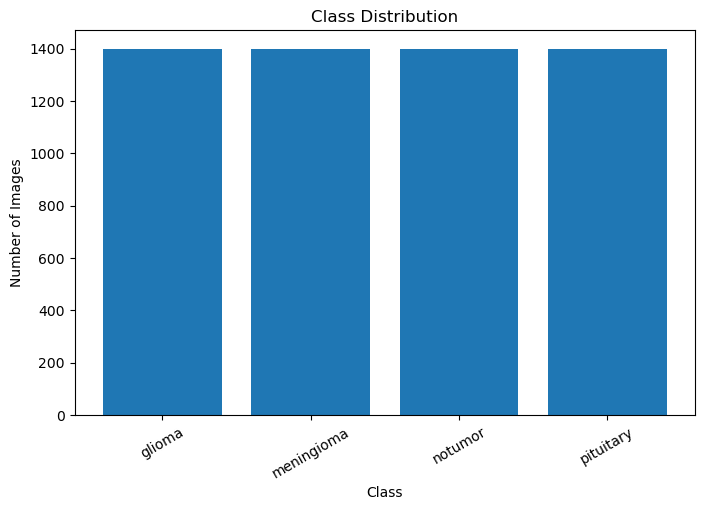

In [8]:
plt.figure(figsize=(8, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Class Distribution")

plt.xticks(rotation=30)

plt.show()

In [9]:
# ============================================
# EXTRA: FULL DATASET
# FOR FUTURE COMPUTER / GPU
# ============================================

# SAMPLES_PER_CLASS = None
#
# TRAIN_PER_CLASS = None
# VAL_PER_CLASS = None
# TEST_PER_CLASS = None
#
# WORKING_DIR = SOURCE_TRAIN_DIR
#
# print("Using the full dataset.")

In [10]:

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

SAMPLES_PER_CLASS = 200

TRAIN_PER_CLASS = 140
VAL_PER_CLASS = 30
TEST_PER_CLASS = 30

WORKING_DIR = "/content/brain_tumor_200"


# ============================================
# CREATE FOLDERS
# ============================================

if os.path.exists(WORKING_DIR):
    shutil.rmtree(WORKING_DIR)

for split in ["train", "val", "test"]:

    for cls in CLASSES:

        os.makedirs(
            os.path.join(
                WORKING_DIR,
                split,
                cls
            ),
            exist_ok=True
        )


# ============================================
# RANDOM SELECTION + SPLIT
# ============================================

for cls in CLASSES:

    source_class_dir = os.path.join(
        SOURCE_TRAIN_DIR,
        cls
    )

    image_files = [
        f
        for f in os.listdir(source_class_dir)
        if f.lower().endswith(IMAGE_EXTENSIONS)
    ]

    random.shuffle(image_files)

    selected = image_files[:SAMPLES_PER_CLASS]

    train_files = selected[:TRAIN_PER_CLASS]

    val_files = selected[
        TRAIN_PER_CLASS:
        TRAIN_PER_CLASS + VAL_PER_CLASS
    ]

    test_files = selected[
        TRAIN_PER_CLASS + VAL_PER_CLASS:
    ]

    splits = {
        "train": train_files,
        "val": val_files,
        "test": test_files
    }

    for split, files in splits.items():

        for filename in files:

            src = os.path.join(
                source_class_dir,
                filename
            )

            dst = os.path.join(
                WORKING_DIR,
                split,
                cls,
                filename
            )

            shutil.copy2(src, dst)


print("200 images per class selected successfully.")

200 images per class selected successfully.


In [11]:
for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")
    total = 0

    for cls in CLASSES:
        folder = os.path.join(WORKING_DIR, split, cls)
        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith(IMAGE_EXTENSIONS)
        ])
        total += count
        print(f"{cls:12s}: {count}")

    print("Total:", total)


TRAIN
glioma      : 140
meningioma  : 140
notumor     : 140
pituitary   : 140
Total: 560

VAL
glioma      : 30
meningioma  : 30
notumor     : 30
pituitary   : 30
Total: 120

TEST
glioma      : 30
meningioma  : 30
notumor     : 30
pituitary   : 30
Total: 120


In [12]:
IMAGE_SIZE = 128
BATCH_SIZE = 16

In [13]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.RandomRotation(10),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [14]:
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [15]:
from genericpath import isfile

In [16]:
class MultiClassClassfication(Dataset): 
    def __init__(self, root_dir, transform=None): 
        super().__init__()

        self.samples = []
        self.transform = transform 
        
        self.Classes = sorted([
            d for d in os.listdir(root_dir) 
            if os.path.isdir(os.path.join(root_dir, d))
        ]) 
        
        self.class_to_idx = {cls_name: idx for idx, cls_name in enumerate(self.Classes)} 

        for cls_name in self.Classes: 
            class_path = os.path.join(root_dir, cls_name) 
            
            for img in os.listdir(class_path): 
                img_path = os.path.join(class_path, img) 
                 
                if os.path.isfile(img_path): 
                    label = self.class_to_idx[cls_name] 
                    self.samples.append((img_path, label))  

    def __len__(self): 
        return len(self.samples) 

    def __getitem__(self, idx): 
        img_path, label = self.samples[idx] 
        image = Image.open(img_path).convert("RGB") 

        if self.transform: 
            image = self.transform(image)

        return image, label

In [17]:
# ============================================================
# CPU DATASET
# ============================================================

train_dataset = MultiClassClassfication(
    root_dir=os.path.join(WORKING_DIR, "train"),
    transform=train_transform
)

val_dataset = MultiClassClassfication(
    root_dir=os.path.join(WORKING_DIR, "val"),
    transform=eval_transform
)

test_dataset = MultiClassClassfication(
    root_dir=os.path.join(WORKING_DIR, "test"),
    transform=eval_transform
)

print("CPU Dataset Created")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

CPU Dataset Created
Train: 560
Validation: 120
Test: 120


In [18]:
# ============================================================
# GPU / FULL DATASET
# ============================================================

# full_train_dataset = MultiClassClassfication(
#     root_dir=os.path.join(DATASET_ROOT, "Training"),
#     transform=train_transform
# )

# full_test_dataset = MultiClassClassfication(
#     root_dir=os.path.join(DATASET_ROOT, "Testing"),
#     transform=eval_transform
# )

# print("GPU / Full Dataset Created")
# print("Training:", len(full_train_dataset))
# print("Testing:", len(full_test_dataset))

In [38]:
train_loader = DataLoader(
    train_dataset,
    batch_size= BATCH_SIZE,
    shuffle= True, 
    num_workers=0
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
) 

print("DataLoaders ready!")

DataLoaders ready!


In [39]:
import os
print("CPU Core numbers:", os.cpu_count())

CPU Core numbers: 8


In [53]:
class SimpleCNN(nn.Module): 
    def __init__(self,num_classes=4): 
        super().__init__() 

        self.features = nn.Sequential(
            nn.Conv2d(3,16,kernel_size= 3,padding= 1),
            nn.BatchNorm2d(16),
            nn.ReLU(), 
            nn.MaxPool2d(2), 

            nn.Conv2d(16,32,kernel_size= 3,padding= 1),
            nn.BatchNorm2d(32),
            nn.ReLU(), 
            nn.MaxPool2d(2), 

            nn.Conv2d(32,64,kernel_size= 3,padding= 1),
            nn.BatchNorm2d(64),
            nn.ReLU(), 
            nn.MaxPool2d(2) 
            
        ) 

        self.classifier = nn.Sequential(
            nn.Flatten() , 

            nn.Linear(64*16*16 , 128), 
            nn.ReLU(), 
            nn.Dropout(0.3), 
            nn.Linear(128,num_classes)
        ) 

    def forward(self,x): 
        x = self. features(x)
        x = self.classifier(x)

        return x 

model = SimpleCNN(num_classes = len(CLASSES)).to(device) 

print(model)
    

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=128, bias=True)

In [54]:
total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params)

Trainable parameters: 2121604


In [55]:
criterion = nn.CrossEntropyLoss() 


optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

EPOCHS = 15 
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []


In [56]:
def train_one_epoch(model,loader,criterion, optimizer, device): 
    running_loss = 0.0
    correct = 0
    total = 0 

    for images ,labels in loader: 
        images = images.to(device) 
        labels = labels.to(device) 

        optimizer.zero_grad() 

        outputs = model(images) 

        loss = criterion(outputs,labels) 

        loss.backward()
        optimizer.step() 


        running_loss += loss.item() * images.size(0) 

        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0) 

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc
        

In [57]:
def evaluate(model, loader, criterion, device): 
    model.eval() 
    running_loss = 0.0
    correct = 0
    total = 0 

    with torch.no_grad() : 
        for images ,labels in loader: 
            images= images.to(device) 
            labels = labels.to(device) 

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc       
    

In [58]:
for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )
     

Epoch [01/15] | Train Loss: 2.9654 | Train Acc: 0.4625 | Val Loss: 0.9905 | Val Acc: 0.5833
Epoch [02/15] | Train Loss: 0.8352 | Train Acc: 0.6768 | Val Loss: 0.7159 | Val Acc: 0.7000
Epoch [03/15] | Train Loss: 0.7200 | Train Acc: 0.7196 | Val Loss: 0.6898 | Val Acc: 0.6833
Epoch [04/15] | Train Loss: 0.6690 | Train Acc: 0.7232 | Val Loss: 0.6872 | Val Acc: 0.7167
Epoch [05/15] | Train Loss: 0.6238 | Train Acc: 0.7446 | Val Loss: 0.5740 | Val Acc: 0.7833
Epoch [06/15] | Train Loss: 0.5599 | Train Acc: 0.7893 | Val Loss: 0.4968 | Val Acc: 0.7500
Epoch [07/15] | Train Loss: 0.5355 | Train Acc: 0.7982 | Val Loss: 0.5470 | Val Acc: 0.7750
Epoch [08/15] | Train Loss: 0.5268 | Train Acc: 0.8018 | Val Loss: 0.6385 | Val Acc: 0.6917
Epoch [09/15] | Train Loss: 0.4572 | Train Acc: 0.8339 | Val Loss: 0.5275 | Val Acc: 0.7667
Epoch [10/15] | Train Loss: 0.3957 | Train Acc: 0.8429 | Val Loss: 0.6516 | Val Acc: 0.7500
Epoch [11/15] | Train Loss: 0.4239 | Train Acc: 0.8339 | Val Loss: 0.6552 | Val 

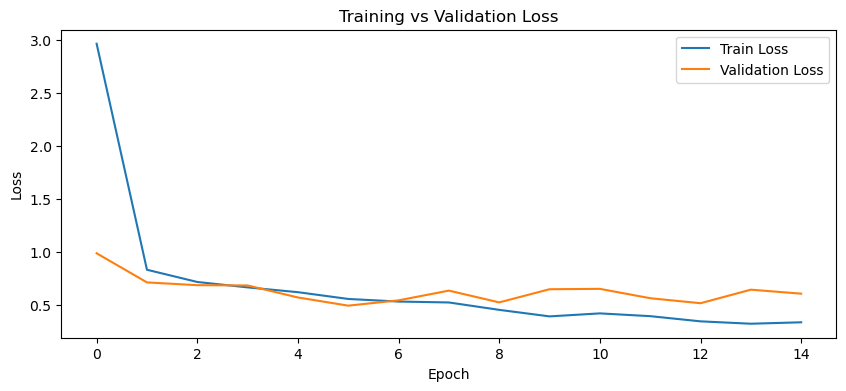

In [59]:
plt.figure(figsize=(10, 4))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

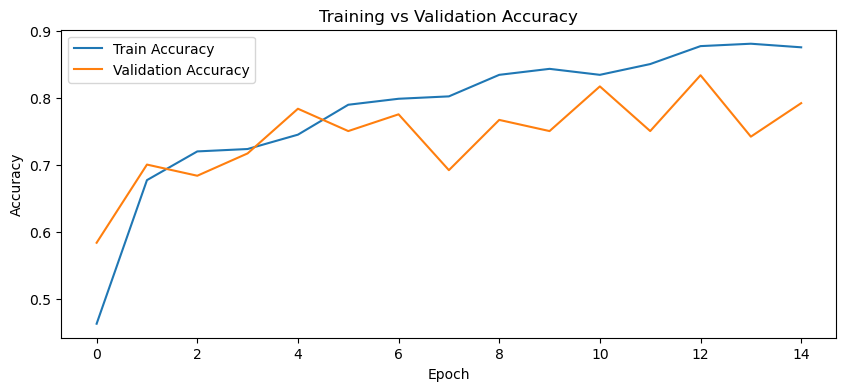

In [60]:
plt.figure(figsize=(10, 4))

plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

In [61]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

test_accuracy = (all_predictions == all_labels).mean()

print(f"Test Accuracy: {test_accuracy:.4f}")

Test Accuracy: 0.8167


In [63]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=test_dataset.Classes,
        digits=4
    )
)

              precision    recall  f1-score   support

      glioma     0.7429    0.8667    0.8000        30
  meningioma     0.8333    0.5000    0.6250        30
     notumor     0.8485    0.9333    0.8889        30
   pituitary     0.8529    0.9667    0.9062        30

    accuracy                         0.8167       120
   macro avg     0.8194    0.8167    0.8050       120
weighted avg     0.8194    0.8167    0.8050       120



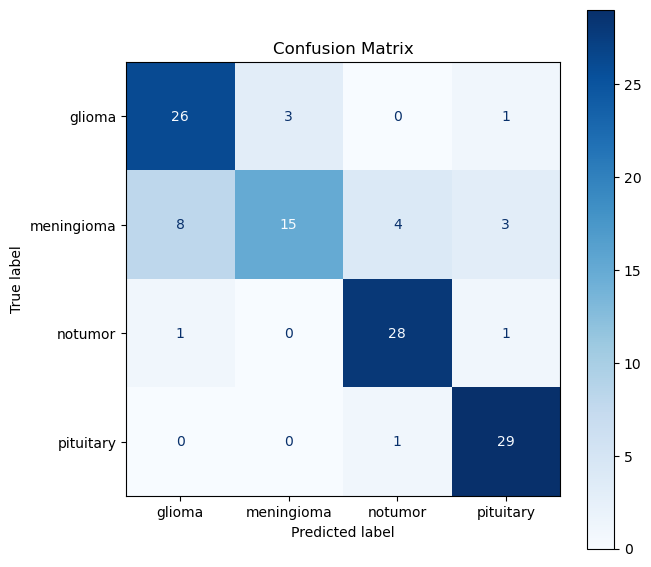

In [65]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.Classes
)

fig, ax = plt.subplots(figsize=(7, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

In [66]:
def predict_image(model, image_path, class_names, device):
    model.eval()

    image = Image.open(image_path).convert("RGB")

    
    input_tensor = eval_transform(image)
    input_tensor = input_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(input_tensor)

        probabilities = torch.softmax(outputs, dim=1)
        confidence, predicted_idx = torch.max(probabilities, dim=1)

    predicted_class = class_names[predicted_idx.item()]
    confidence = confidence.item()

    return image, predicted_class, confidence, probabilities.cpu().numpy()[0]

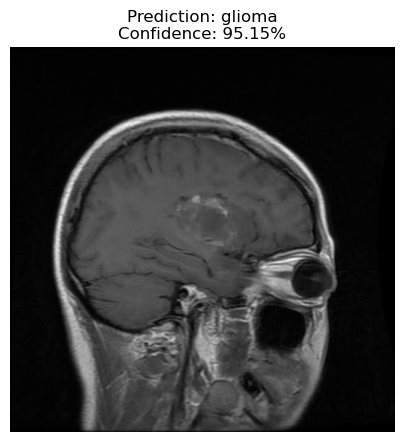

Image: /content/brain_tumor_200\test\glioma\Tr-gl_100.jpg
Predicted class: glioma
Confidence: 95.15%

Class probabilities:
glioma      : 95.15%
meningioma  : 4.84%
notumor     : 0.00%
pituitary   : 0.00%


In [69]:
sample_path = test_dataset.samples[0][0]

image, predicted_class, confidence, probabilities = predict_image(
    model,
    sample_path,
    test_dataset.Classes,
    device
)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2%}"
)
plt.axis("off")
plt.show()

print("Image:", sample_path)
print("Predicted class:", predicted_class)
print("Confidence:", f"{confidence:.2%}")

print("\nClass probabilities:")
for class_name, prob in zip(test_dataset.Classes, probabilities):
    print(f"{class_name:12s}: {prob:.2%}")